# Reddit Riddles: LLM Reasoning Evaluation

This notebook evaluates Large Language Models (LLMs) on Reddit riddles.

## Project Overview

The goal is to:
1. Extract problem/solution pairs from Reddit riddle threads
2. Evaluate existing LLMs on these problems
3. Implement proper evaluation metrics for comparing LLM outputs to ground truth

## Setup Instructions

**Before running this notebook:**
1. Create a `.env` file in the `nlp-project` directory with your OpenRouter API key:
   ```
   OPENROUTER_API_KEY=your_openrouter_api_key_here
   ```
2. Install required packages:
   ```bash
   pip install datasets pandas numpy openai python-dotenv sentence-transformers scikit-learn matplotlib seaborn tqdm
   ```

## Dataset
- Source: https://huggingface.co/datasets/sileod/reddit-riddles
- Posts: Riddles with metadata (title, body, flair, etc.)
- Comments: Potential solutions and discussions

For more information see the file  `node.md`

All of these code we will implement,  will be well commented in order to help the user to have a good understanding, please check the docstring of the code

## Evaluation Challenge
Comparing LLM outputs to ground truth is non-trivial because:
- Answers can be expressed in different ways
- Some riddles have multiple valid answers
- Format and style may vary
- Semantic equivalence matters more than exact match


In [1]:
# Import required libraries
from datasets import load_dataset
import pandas as pd
import numpy as np
import re
import os
import json
from pathlib import Path
from datetime import datetime
from typing import Any, Dict, List, Optional, Tuple, Union
from tqdm import tqdm
import concurrent.futures

# LLM and evaluation
from openai import OpenAI
from dotenv import load_dotenv
import sentence_transformers
from sklearn.metrics.pairwise import cosine_similarity

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Load environment variables
load_dotenv()

print("Libraries imported successfully.")


2025-11-14 16:47:02.330395: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-11-14 16:47:03.313799: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-11-14 16:47:06.934665: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Libraries imported successfully.


In [2]:
# Setup OpenAI client for OpenRouter
OPENROUTER_API_KEY = os.getenv("OPENROUTER_API_KEY")

if not OPENROUTER_API_KEY:
    raise ValueError("OPENROUTER_API_KEY not found in environment variables. Please set it in .env file.")

# Initialize OpenAI client with OpenRouter
client = OpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=OPENROUTER_API_KEY,
)

# Initialize sentence transformer for semantic similarity evaluation
print("Loading sentence transformer model for evaluation...")
similarity_model = sentence_transformers.SentenceTransformer('all-MiniLM-L6-v2')
print("Setup complete.")


Loading sentence transformer model for evaluation...
Setup complete.


## Step 1: Load and Explore Dataset


In [3]:
def load_reddit_riddles_dataset():
    '''
    Loads the Reddit riddles dataset from HuggingFace.
    
    :return: Tuple of (posts DataFrame, comments DataFrame)
    :type: Tuple[pd.DataFrame, pd.DataFrame]
    '''
    print("Loading datasets...")
    posts = load_dataset("sileod/reddit-riddles", "submissions")["train"]
    comments = load_dataset("sileod/reddit-riddles", "comments")["train"]
    
    print(f"Loaded {len(posts)} posts and {len(comments)} comments")
    
    # Convert to pandas DataFrames
    posts_df = posts.to_pandas()
    comments_df = comments.to_pandas()
    
    return posts_df, comments_df

# Load datasets
posts_df, comments_df = load_reddit_riddles_dataset()

print(f"\nPosts columns: {posts_df.columns.tolist()}")
print(f"Comments columns: {comments_df.columns.tolist()}")


Loading datasets...
Loaded 40749 posts and 429164 comments

Posts columns: ['author', 'created_utc', 'is_self', 'link_flair_text', 'num_comments', 'permalink', 'score', 'selftext', 'subreddit', 'title', 'url', 'upvote_ratio', 'post_id']
Comments columns: ['subreddit', 'link_id', 'id', 'body', 'score', 'author', 'created_utc', 'parent_id', 'permalink']


## Dataset Columns Overview

This section describes all columns in the Reddit Riddles dataset. For detailed information about each column, please refer to `notes.md`.

### Posts Dataset Columns
- **author**: Reddit username of the post creator
- **created_utc**: Unix timestamp of when the post was created
- **is_self**: Boolean indicating if the post is a self-post (text-only)
- **link_flair_text**: Post category/flair (e.g., "Solved", "Unsolved")
- **num_comments**: Number of comments on the post
- **permalink**: Reddit URL path to the post
- **score**: Upvote score of the post
- **selftext**: Full text content of the post (riddle text)
- **subreddit**: Subreddit name (should be "riddles")
- **title**: Post title
- **url**: Full Reddit URL
- **upvote_ratio**: Ratio of upvotes to total votes
- **post_id**: Unique post identifier (extracted from URL)

### Comments Dataset Columns
- **subreddit**: Subreddit name
- **link_id**: ID of the post the comment belongs to (with "t3_" prefix)
- **id**: Unique comment identifier
- **body**: Text content of the comment
- **score**: Upvote score of the comment
- **author**: Reddit username of the comment author
- **created_utc**: Unix timestamp of when the comment was created
- **parent_id**: ID of the parent (post or comment this replies to)
- **permalink**: Reddit URL path to the comment

> **Note**: For comprehensive details about data types, filtering criteria, and preprocessing steps, see `notes.md` where we add this.

In [4]:
# Basic statistics
print("=== DATASET STATISTICS ===")
print(f"Total posts: {len(posts_df)}")
print(f"Solved posts: {(posts_df['link_flair_text'] == 'Solved').sum()}")
print(f"Unsolved posts: {(posts_df['link_flair_text'] == 'Unsolved').sum()}")
print(f"Self posts (text only): {posts_df['is_self'].sum()}")
print(f"External link posts: {(~posts_df['is_self']).sum()}")
print(f"\nTotal comments: {len(comments_df)}")
print(f"Comments with positive scores: {(comments_df['score'] > 0).sum()}")
print(f"Average comment score: {comments_df['score'].mean():.2f}")


=== DATASET STATISTICS ===
Total posts: 40749
Solved posts: 11579
Unsolved posts: 3290
Self posts (text only): 38830
External link posts: 1919

Total comments: 429164
Comments with positive scores: 409009
Average comment score: 2.80


## Implementation Notes

These utilities are designed to be easy to extend so future contributors can add new ideas with minimal changes.

To help future user to add their ideas or strategy, we do:
- Write small, focused functions with clear docstrings and type hints.
- Keep logic modular (separate extraction, cleaning, selection, LLM calls, and evaluation).
- Minimize side effects: return values rather than mutating global state when possible.
- Expose behavior via parameters and configuration (e.g., `strategy`, `max_comments`, `use_top_level_only`) so new strategies can be added without editing core logic.

For the LLM usage, we add parallelism
- Use parallel processing to speed up LLM-based operations, but make concurrency configurable (e.g., `max_workers`) so it can be tuned to API rate limits.
- Implement robust rate limiting, exponential backoff, and retries around API calls.
- Avoid unnecessary repeated calls by:
    - Caching LLM judgments / predictions keyed by (model, prompt) when appropriate.
    - Limiting the number of comments sent to the LLM (`max_comments`) and pre-filtering by score.

## Step 2: Extract Problem/Solution Pairs


## Prepare dataset & extraction strategies (post → solution)

This section prepares the dataset and describes configurable strategies to build post→solution pairs. It also documents key filters and recommended LLM hyperparameters so you can tune behavior without editing core logic.

### Overview
- We support multiple strategies for selecting the best solution comment for each riddle.
- You can choose whether to consider only top-level comments (direct replies) or include nested replies.
- Two built-in strategies we used:
    - `score_based`: pick the highest-scoring (positive) comment.
    - `llm_based`: ask an LLM to evaluate the top N comments and either return the best or reject them all if no one satisfy really.

### How to add new strategies
- Implement a selector function with signature similar to:
    - `select_best_answer_newstrategy(riddle_text, comments_for_post, use_top_level_only, **kwargs) -> Optional[pd.Series]`
- Expose the strategy via the `strategy` argument in `extract_problem_solution_pairs`.
- Keep logic small, well-documented. We prefer returning `None` when no satisfactory answer is found.

### Filters & preprocessing (adjustable)
- Posts
    - Keep solved self-posts by default: `link_flair_text == "Solved"` and `is_self == True`.
    - Minimum post score: default `min_score=5` (tunable).
    - Minimum riddle length: default `min_text_length=10` chars.
    - Combine `title` + `selftext` into `riddle_text`.
- Comments
    - Remove `[deleted]`, `[removed]`, empty bodies.
    - Extract `post_id` from `link_id` (`t3_...`).
    - Optionally only consider top-level comments (`parent_id` starts with `t3_`).
    - Consider filtering by `score > 0` to reduce noise.

Adjust these thresholds when you want a stricter or broader dataset. Stricter filters reduce false positives but may discard valid pairs.

### LLM strategy & recommended hyperparameters for the future user
- Purpose: let the LLM evaluate semantic correctness among the top candidate comments and optionally reject all.
- Tuneable parameters:
    - `model`: e.g., `"openai/gpt-4o-mini"` (or other OpenRouter-compatible models).
    - `temperature`: low values for consistent judgments. Recommended `0.0–0.3` (default `0.1`).
    - `max_tokens` (response length): `100–256` depending on prompt verbosity (default `100–200`).
    - `max_comments`: number of top comments to send to the LLM (default `30`).
    - `max_workers`: parallel threads for LLM calls (default `5–10`, adjust for rate limits).
- Robustness tips:
    - Cache (model, prompt) -> judgement to avoid repeated calls.
    - Implement retries & exponential backoff.
    - Add timeouts and graceful fallback (e.g., fall back to `score_based` on LLM errors).

### Trade-offs
This is obvious of course: 
- `score_based` is fast, deterministic, and cheap but can pick highly-upvoted incorrect answers.
- `llm_based` is more semantic and can reject bad threads, but it is slower and costlier (this is why we select just some comments with high score like $30$ comments).
- A hybrid approach (use `score_based` as fallback for LLM errors or pre-filter high-score candidates) is often practical.

Use these notes to adapt filters, add strategies, and select sensible LLM hyperparameters for your experiments.

In [5]:
def extract_post_id(link_id):
    '''
    Extracts post_id from link_id format 't3_xxxxx'.
    
    Reddit uses prefixes: 't3_' for posts, 't1_' for comments.
     - t3_ means: responding to a post
     - t1_ means: responding to a comment (nested)
     in our case, we want to extract the post ID from link_id.
    
    :param link_id: Link ID with prefix (e.g., 't3_xxxxx')
    :type link_id: str
    :return: Post ID without prefix, or None if invalid
    :type: Optional[str]
    '''
    if pd.isna(link_id):
        return None
    if isinstance(link_id, str) and link_id.startswith('t3_'):
        return link_id[3:]  # Remove 't3_' prefix
    return link_id


def filter_solved_posts(posts_df, min_score=5, min_text_length=10):
    '''
    Filters posts to only include solved, text-based riddles.
    
    :param posts_df: DataFrame with posts data
    :param min_score: Minimum post score to include (default = 5)
    :param min_text_length: Minimum text length in characters (default = 10)
    :type posts_df: pd.DataFrame
    :type min_score: int
    :type min_text_length: int
    :return: Filtered DataFrame with solved posts
    :type: pd.DataFrame
    '''
    # Filter for solved, self-posts with text
    solved_posts = posts_df[
        (posts_df['link_flair_text'] == "Solved") &
        (posts_df['is_self'] == True) &
        (posts_df['selftext'].notna()) &
        (posts_df['selftext'].str.len() > 0) &
        (posts_df['score'] > min_score)
    ].copy()
    
    # Combine title and selftext to create full riddle text
    solved_posts['riddle_text'] = (
        solved_posts['title'].fillna('') + '\n\n' + solved_posts['selftext'].fillna('')
    ).str.strip()
    
    # Remove very short posts
    solved_posts = solved_posts[solved_posts['riddle_text'].str.len() >= min_text_length].copy()
    
    return solved_posts


def prepare_comments(comments_df):
    '''
    Prepares comments for matching with posts.
    
    Extracts post_id from link_id and identifies top-level comments
    (direct replies to posts vs nested comments).
    
    :param comments_df: DataFrame with comments data
    :type comments_df: pd.DataFrame
    :return: Processed DataFrame with post_id and is_top_level columns
    :type: pd.DataFrame
    '''
    # Clean comments: remove deleted/removed
    valid_comments = comments_df[
        (comments_df['body'].notna()) &
        (~comments_df['body'].str.lower().isin(['[deleted]', '[removed]', ''])) &
        (comments_df['body'].str.len() >= 1)
    ].copy()
    
    # Extract post_id from link_id
    valid_comments['post_id'] = valid_comments['link_id'].apply(extract_post_id)
    
    # Identify top-level comments (direct replies to post)
    # Top-level: parent_id starts with 't3_' (post)
    # Nested: parent_id starts with 't1_' (comment)
    valid_comments['is_top_level'] = (
        valid_comments['parent_id'].str.startswith('t3_') 
        if valid_comments['parent_id'].notna().any() 
        else pd.Series([False] * len(valid_comments))
    )
    
    return valid_comments


def select_best_answer(comments_for_post, use_top_level_only=True):
    '''
    Selects the best answer from comments for a given post.
    
    Strategy: Highest positive score among top-level comments (or all comments).
    
    :param comments_for_post: DataFrame with comments for a specific post
    :param use_top_level_only: If True, only consider top-level comments (default = True)
    :type comments_for_post: pd.DataFrame
    :type use_top_level_only: bool
    :return: Best comment as Series, or None if no valid answer found
    :type: Optional[pd.Series]
    '''
    if len(comments_for_post) == 0:
        return None
    
    # Filter for top-level comments if requested
    if use_top_level_only:
        comments_for_post = comments_for_post[comments_for_post['is_top_level']]
        if len(comments_for_post) == 0:
            return None
    
    # Filter for positive scores only
    positive_comments = comments_for_post[comments_for_post['score'] > 0] # Only consider positive scores for the comment selection
    if len(positive_comments) == 0:
        return None
    
    # Get comment with highest score
    best_comment = positive_comments.loc[positive_comments['score'].idxmax()]
    return best_comment


def select_best_answer_with_llm(riddle_text, comments_for_post, use_top_level_only=True, 
                                  model="openai/gpt-4o-mini", max_comments=30):
    '''
    Uses an LLM to select the best answer from comments for a given riddle.
    
    The LLM evaluates all comments and can reject all of them if none are satisfactory.
    
    :param riddle_text: The riddle text (problem)
    :param comments_for_post: DataFrame with comments for a specific post
    :param use_top_level_only: If True, only consider top-level comments (default = True)
    :param model: Model identifier for OpenRouter (default = "openai/gpt-4o-mini")
    :param max_comments: Maximum number of comments to evaluate (default = 30)
    :type riddle_text: str
    :type comments_for_post: pd.DataFrame
    :type use_top_level_only: bool
    :type model: str
    :type max_comments: int
    :return: Best comment as Series, or None if no valid answer found or LLM rejects all
    :type: Optional[pd.Series]
    '''
    if len(comments_for_post) == 0:
        return None
    
    # Filter for top-level comments if requested
    if use_top_level_only:
        comments_for_post = comments_for_post[comments_for_post['is_top_level']]
        if len(comments_for_post) == 0:
            return None
    
    # Limit number of comments to avoid token limits (prioritize by score)
    comments_to_evaluate = comments_for_post.nlargest(max_comments, 'score')
    
    if len(comments_to_evaluate) == 0:
        return None
    
    # Format comments for LLM
    comments_list = []
    for idx, (comment_idx, comment) in enumerate(comments_to_evaluate.iterrows()):
        comment_text = comment['body'].strip()
        comment_score = comment['score']
        comments_list.append(f"Comment {idx + 1} (Score: {comment_score}): {comment_text}")
    
    comments_text = "\n\n".join(comments_list)
    
    # Create prompt for LLM
    prompt = f"""You are evaluating potential answers to a riddle. Your task is to identify which comment best answers the riddle, or reject all comments if none provide a satisfactory solution.
    Don't answer the riddle yourself; only evaluate the provided comments.
RIDDLE:
{riddle_text}

POTENTIAL ANSWERS:
{comments_text}

Please analyze each comment and determine which one is the best answer to the riddle. Consider:
1. Does it directly answer the riddle?
2. Does it make logical sense?
3. Is it a complete answer?

If you find a good answer, respond with ONLY the number of the comment (e.g., "1" or "2" or "3", etc.).
If NONE of the comments provide a satisfactory answer to the riddle, respond with "NONE" or "REJECT".

Respond with ONLY the number or "NONE"/"REJECT". Do not include any other text."""

    try:
        response = client.chat.completions.create(
            model=model,
            messages=[
                {
                    "role": "user",
                    "content": prompt
                }
            ],
            temperature=0.1,  # Low temperature for consistent results
            max_tokens=100,
        )
        
        # Extract the response
        answer_text = response.choices[0].message.content.strip().upper()
        
        # Check if LLM rejected all comments
        if "NONE" in answer_text or "REJECT" in answer_text:
            return None
        
        # Extract comment number from response
        match = re.search(r'\d+', answer_text)
        if match:
            comment_num = int(match.group()) - 1  # Convert to 0-based index
            if 0 <= comment_num < len(comments_to_evaluate):
                # Return the selected comment
                selected_comment = comments_to_evaluate.iloc[comment_num]
                return selected_comment
        
        # If parsing fails, return None (reject)
        return None
        
    except Exception as e:
        print(f"LLM error in select_best_answer_with_llm: {e}")
        # Fallback to highest score strategy
        positive_comments = comments_for_post[comments_for_post['score'] > 0]
        if len(positive_comments) > 0:
            return positive_comments.loc[positive_comments['score'].idxmax()]
        return None


In [6]:
def process_single_post(post_data, comments_by_post, use_top_level_only, strategy, llm_model):
    '''
    Processes a single post to extract problem/solution pair.
    
    Helper function for parallel processing. Uses select_best_answer and select_best_answer_with_llm
    from the global scope (these functions must be defined before this function).
    
    :param post_data: Tuple of (post_id, post_row) where post_row is a Series
    :param comments_by_post: GroupBy object with comments grouped by post_id
    :param use_top_level_only: If True, only consider top-level comments
    :param strategy: Strategy for selecting best answer
    :param llm_model: Model identifier for OpenRouter
    :type post_data: Tuple[str, pd.Series]
    :type comments_by_post: pd.core.groupby.DataFrameGroupBy
    :type use_top_level_only: bool
    :type strategy: str
    :type llm_model: str
    :return: Dictionary with problem/solution pair or None, and rejection status
    :type: Tuple[Optional[Dict], bool]
    '''
    post_id, post_row = post_data
    
    if post_id not in comments_by_post.groups:
        return None, False
    
    comments_for_post = comments_by_post.get_group(post_id)
    
    # Select best answer based on strategy
    # Note: select_best_answer and select_best_answer_with_llm are used from global scope
    if strategy == "llm_based":
        best_answer = select_best_answer_with_llm(
            post_row['riddle_text'], 
            comments_for_post, 
            use_top_level_only=use_top_level_only,
            model=llm_model
        )
        rejected = (best_answer is None)
    else:  # score_based (default)
        best_answer = select_best_answer(comments_for_post, use_top_level_only=use_top_level_only)
        rejected = False
    
    if best_answer is not None:
        # Clean answer text (remove Reddit spoiler tags)
        answer_text = best_answer['body']
        answer_text = re.sub(r'&gt;!', '', answer_text)
        answer_text = re.sub(r'!&lt;', '', answer_text)
        answer_text = re.sub(r'&lt;', '', answer_text)
        answer_text = re.sub(r'&gt;', '', answer_text)
        answer_text = re.sub(r'\[/?spoiler\]', '', answer_text, flags=re.IGNORECASE)
        answer_text = re.sub(r'\(?\s*spoiler\s*\)?', '', answer_text, flags=re.IGNORECASE)
        answer_text = re.sub(r'\*\*?spoiler\*\*?', '', answer_text, flags=re.IGNORECASE)
        answer_text = re.sub(r'(?i)\b(answer|solution|riddle answer|correct answer|my guess|i think it\'s)\b[:\-]?', '', answer_text)
        answer_text = re.sub(r'(?i)\bthe answer is\b[:\-]?', '', answer_text)
        answer_text = re.sub(r'(?i)\bthat would be\b[:\-]?', '', answer_text)
        answer_text = re.sub(r'\*{1,2}', '', answer_text)
        answer_text = re.sub(r'[_~>`#]', '', answer_text)
        answer_text = re.sub(r'\s+', ' ', answer_text)
        answer_text = answer_text.strip()
        
        return {
            'post_id': post_id,
            'problem': post_row['riddle_text'],
            'solution': answer_text,
            'solution_score': best_answer['score'],
            'solution_is_top_level': best_answer['is_top_level'],
            'num_comments': len(comments_for_post),
            'title': post_row['title'],
            'strategy': strategy
        }, rejected
    
    return None, rejected


def extract_problem_solution_pairs(posts_df, comments_df, use_top_level_only=True, 
                                     strategy="score_based", llm_model="openai/gpt-4o-mini",
                                     sample_size=None, max_workers=10):
    '''
    Extracts problem/solution pairs from posts and comments.
    
    Supports multiple strategies for selecting the best answer:
    - "score_based": Uses highest scoring comment (default)
    - "llm_based": Uses LLM to evaluate and select best answer, can reject if none are good
    
    When using "llm_based" strategy, processes posts in parallel using ThreadPoolExecutor
    for much faster execution.
    
    :param posts_df: DataFrame with filtered solved posts
    :param comments_df: DataFrame with processed comments
    :param use_top_level_only: If True, only consider top-level comments (default = True)
    :param strategy: Strategy for selecting best answer - "score_based" or "llm_based" (default = "score_based")
    :param llm_model: Model identifier for OpenRouter when using "llm_based" strategy (default = "openai/gpt-4o-mini")
    :param sample_size: Number of posts to sample (None = process all posts)
    :param max_workers: Maximum number of parallel workers for LLM strategy (default = 10)
                        Adjust based on API rate limits. Higher = faster but may hit rate limits.
    :type posts_df: pd.DataFrame
    :type comments_df: pd.DataFrame
    :type use_top_level_only: bool
    :type strategy: str
    :type llm_model: str
    :type sample_size: Optional[int]
    :type max_workers: int
    :return: DataFrame with problem/solution pairs
    :type: pd.DataFrame
    '''
    # Filter solved posts
    solved_posts = filter_solved_posts(posts_df)
    print(f"Filtered to {len(solved_posts)} solved self-posts")
    
    # Apply limited sample if requested
    if sample_size is not None and sample_size < len(solved_posts):
        solved_posts = solved_posts.head(sample_size).copy()
        print(f"Processing {len(solved_posts)} posts")
    
    # Prepare comments
    valid_comments = prepare_comments(comments_df)
    print(f"Valid comments: {len(valid_comments)}")
    
    # Group comments by post_id
    comments_by_post = valid_comments.groupby('post_id')
    
    # Extract problem/solution pairs
    problem_solution_pairs = []
    rejected_posts = 0
    
    print(f"Using strategy: {strategy}")
    
    # Prepare post data as list of tuples
    post_data_list = [(row['post_id'], row) for _, row in solved_posts.iterrows()]
    
    if strategy == "llm_based":
        # Use parallel processing for LLM strategy
        print(f"Using parallel processing with {max_workers} workers...")
        print("Note: Please, adjust max_workers based on your API rate limits, in my case I use 10 workers for default.")
        
        with concurrent.futures.ThreadPoolExecutor(max_workers=max_workers) as executor:
            # Submit all tasks
            future_to_post = {
                executor.submit(
                    process_single_post, 
                    post_data, 
                    comments_by_post, 
                    use_top_level_only, 
                    strategy, 
                    llm_model
                ): post_data[0] 
                for post_data in post_data_list
            }
            
            # Process completed tasks with progress bar
            with tqdm(total=len(post_data_list), desc="Extracting pairs (parallel)") as pbar:
                for future in concurrent.futures.as_completed(future_to_post):
                    post_id = future_to_post[future]
                    try:
                        result, rejected = future.result()
                        if result is not None:
                            problem_solution_pairs.append(result)
                        if rejected:
                            rejected_posts += 1
                    except Exception as e:
                        print(f"\nError processing post {post_id}: {e}")
                    pbar.update(1)
    else:
        # Sequential processing for score-based strategy (fast enough)
        for post_data in tqdm(post_data_list, desc="Extracting pairs"):
            result, rejected = process_single_post(
                post_data, 
                comments_by_post, 
                use_top_level_only, 
                strategy, 
                llm_model
            )
            if result is not None:
                problem_solution_pairs.append(result)
            if rejected:
                rejected_posts += 1
    
    pairs_df = pd.DataFrame(problem_solution_pairs)
    print(f"\nExtracted {len(pairs_df)} problem/solution pairs")
    if strategy == "llm_based" and rejected_posts > 0:
        print(f"LLM rejected {rejected_posts} posts (no satisfactory answer found)")
        if len(post_data_list) > 0:
            print(f"Rejection rate: {rejected_posts / len(post_data_list) * 100:.1f}%")
    
    return pairs_df

## Step 3: LLM prediction and Evaluation

## Riddle Evaluation Utilities

This section implements the riddle evaluation pipeline: generating LLM answers and scoring them against the dataset ground truth.

What you'll find here
- Small, focused functions with docstrings:
    - Prompt & solve: `create_riddle_prompt`, `solve_riddle_with_llm`
    - Judgment: `judge_with_llm` (LLM-as-a-judge)
    - Text metrics: `normalize_text`, `exact_match_score`, `semantic_similarity_score`, `contains_keywords`, `token_f1_score`
    - Orchestration: `evaluate_answer`, `process_single_riddle_evaluation`, `evaluate_llm_on_riddles`
- Parallel evaluation support (ThreadPoolExecutor).

In [7]:
def create_riddle_prompt(problem_text):
    '''
    Creates a prompt for LLM to solve a riddle.
    
    :param problem_text: The riddle text (problem)
    :type problem_text: str
    :return: Formatted prompt string
    :type: str
    '''
    prompt = f"""Solve the following riddle. Provide your answer clearly and concisely.

    RIDDLE:
    {problem_text}

    ANSWER:"""
    return prompt


def solve_riddle_with_llm(problem_text, model="openai/gpt-4o-mini", temperature=0.1, max_tokens=200):
    '''
    Uses an LLM to solve a riddle.
    
    :param problem_text: The riddle text (problem)
    :param model: Model identifier for OpenRouter (default = "openai/gpt-4o-mini")
    :param temperature: Sampling temperature (default = 0.1)
    :param max_tokens: Maximum tokens in response (default = 200)
    :type problem_text: str
    :type model: str
    :type temperature: float
    :type max_tokens: int
    :return: LLM's answer to the riddle, or None if error
    :type: Optional[str]
    '''
    prompt = create_riddle_prompt(problem_text)
    
    try:
        response = client.chat.completions.create(
            model=model,
            messages=[
                {
                    "role": "user",
                    "content": prompt
                }
            ],
            temperature=temperature,
            max_tokens=max_tokens
        )
        
        answer = response.choices[0].message.content.strip()
        return answer
    except Exception as e:
        print(f"Error calling LLM: {e}")
        return None

## Riddle Evaluation: Metrics and LLM-as-a-Judge

We evaluate LLM predictions against ground-truth answers using a set of complementary metrics and—optionally—an LLM acting as an impartial judge. A well-crafted judge prompt helps capture semantic equivalence (paraphrases, synonyms, minor formatting differences) that simple string metrics miss.

We normalize before use the evaluate on some metrics 

Normalization: lowercase + punctuation removal for robust text matching.

Key metrics
- Exact match: strict equality after normalization (useful but narrow).
- Token-level F1: measures overlap of meaningful tokens (precision/recall).
- Keyword overlap: fraction of important ground-truth words present in the prediction.
- Semantic similarity: embedding-based cosine similarity (sentence-transformers).
- LLM-as-a-Judge: a model that scores semantic equivalence and returns a compact numeric judgment (e.g., JSON with a score and label).

LLM-as-a-Judge: we design prompts to emphasize semantic equivalence, user can improve this prompt of course.

Recommended judge model
- We use `kanthropic/claude-3-haiku` as the judge in experiments, we want to use a model different of the model that we take to predict the llms answer from the riddles.

Notes: we expect some metrics (like exact match) to under-report correctness when paraphrases are common; the judge and semantic measures help compensate.

In [8]:
def judge_with_llm(predicted_answer, ground_truth_answer, model="openai/gpt-4o-mini", return_raw=False):
    '''
    Uses an LLM-as-a-Judge to score how well the predicted answer matches the ground truth.
    Returns a dict with 'judge_score' (float in [0,1]) and 'judge_label' ("correct"/"incorrect").
    Optionally includes raw LLM content when return_raw=True.
    '''
    try:
        # Quick shortcut for empty inputs
        if not (predicted_answer and ground_truth_answer):
            result = {"judge_score": 0.0, "judge_label": "incorrect"}
            if return_raw:
                result["raw"] = ""
            return result

        prompt = f"""
You are an expert evaluator for riddle answers. Compare the PREDICTED ANSWER to the GROUND TRUTH.
Judge SEMANTIC EQUIVALENCE, allowing for paraphrases, synonyms, minor formatting, or spoiler markup.
If the predicted answer expresses the same solution as the ground truth, it is CORRECT, even if phrased differently.
If it is unrelated, contradicts, or misses key information, it is INCORRECT.

GROUND TRUTH:
{ground_truth_answer}

PREDICTED:
{predicted_answer}

Scoring rubric:
- 1.0 = clearly equivalent; matches the intended solution
- 0.75 = mostly equivalent; minor omissions/formatting differences (still "correct")
- 0.5 = partially related; could be interpreted as similar but incomplete/ambiguous
- 0.25 = weakly related; vague or off-target
- 0.0 = not equivalent

Return ONLY a compact JSON object (no prose, no code fences) with at least the key "score" (a number between 0 and 1).
Example: {{"score": 1.0}}
You may optionally include a "label" field with "correct" or "incorrect".
"""
        response = client.chat.completions.create(
            model=model,
            messages=[{"role": "system", "content": "You are an impartial evaluator."},
                      {"role": "user", "content": prompt}],
            temperature=0.0,
            max_tokens=200
        )

        # Extract content robustly
        content = ""
        try:
            content = response.choices[0].message.content.strip()
        except Exception:
            # fallback if structure differs
            content = getattr(response.choices[0], "text", "").strip()

        score = None
        label = None

        # Try to parse JSON
        try:
            parsed = json.loads(content)
            if isinstance(parsed, dict):
                # common keys to look for
                score = parsed.get("score") or parsed.get("judge_score") or parsed.get("value")
                label = parsed.get("label") or parsed.get("judgement") or parsed.get("result")
                # if score is a string, try to convert
                if isinstance(score, str):
                    try:
                        score = float(score)
                    except Exception:
                        score = None
        except Exception:
            parsed = None

        # If no numeric score from JSON, try to extract numeric pattern
        if score is None:
            m = re.search(r'([01](?:\.\d+)?)', content)
            if m:
                try:
                    score = float(m.group(1))
                except Exception:
                    score = None

        # If still no score, infer from keywords
        if score is None:
            if re.search(r'\b(correct|yes|true|1\.0|1)\b', content, flags=re.I):
                score = 1.0
            elif re.search(r'\b(incorrect|no|false|0\.0|0)\b', content, flags=re.I):
                score = 0.0
            else:
                score = 0.0  # conservative default

        # Clamp score to [0,1]
        try:
            score = float(score)
        except Exception:
            score = 0.0
        score = max(0.0, min(1.0, score))

        # Derive label if not present
        if not label:
            label = "correct" if score >= 0.75 else "incorrect"
        else:
            label = str(label).strip().lower()
            if label not in ("correct", "incorrect"):
                label = "correct" if score >= 0.75 else "incorrect"

        result = {"judge_score": score, "judge_label": label}
        if return_raw:
            result["raw"] = content
        return result

    except Exception as exc:
        print(f"Judge LLM error: {exc}")
        return {"judge_score": 0.0, "judge_label": "incorrect", **({"raw": ""} if return_raw else {})}

In [9]:
def normalize_text(text):
    '''
    Normalizes text for comparison by removing punctuation and converting to lowercase.
    
    :param text: Text to normalize
    :type text: str
    :return: Normalized text
    :type: str
    '''
    # Convert to lowercase
    text = text.lower()
    # Remove punctuation
    text = re.sub(r'[^\w\s]', '', text)
    # Remove extra whitespace
    text = ' '.join(text.split())
    return text


def exact_match_score(predicted_answer, ground_truth_answer):
    '''
    Computes exact match score between predicted and ground truth answers.
    
    :param predicted_answer: LLM's predicted answer
    :param ground_truth_answer: Ground truth answer from dataset
    :type predicted_answer: str
    :type ground_truth_answer: str
    :return: 1.0 if exact match (after normalization), 0.0 otherwise
    :type: float
    '''
    pred_norm = normalize_text(predicted_answer)
    truth_norm = normalize_text(ground_truth_answer)
    
    return 1.0 if pred_norm == truth_norm else 0.0


def semantic_similarity_score(predicted_answer, ground_truth_answer, model=None):
    '''
    Computes semantic similarity score between predicted and ground truth answers.
    
    Uses sentence transformers to compute cosine similarity of embeddings.
    
    :param predicted_answer: LLM's predicted answer
    :param ground_truth_answer: Ground truth answer from dataset
    :param model: Sentence transformer model (default = None, uses global model)
    :type predicted_answer: str
    :type ground_truth_answer: str
    :type model: Optional[sentence_transformers.SentenceTransformer]
    :return: Cosine similarity score between 0 and 1
    :type: float
    '''
    if model is None:
        model = similarity_model
    
    # Get embeddings
    embeddings = model.encode([predicted_answer, ground_truth_answer])
    
    # Compute cosine similarity
    similarity = cosine_similarity([embeddings[0]], [embeddings[1]])[0][0]
    
    return float(similarity)


def contains_keywords(predicted_answer, ground_truth_answer):
    '''
    Checks if predicted answer contains key words from the ground truth.
    
    :param predicted_answer: LLM's predicted answer
    :param ground_truth_answer: Ground truth answer from dataset
    :type predicted_answer: str
    :type ground_truth_answer: str
    :return: Ratio of ground truth words found in predicted answer
    :type: float
    '''
    pred_words = set(normalize_text(predicted_answer).split())
    truth_words = set(normalize_text(ground_truth_answer).split())
    
    if len(truth_words) == 0:
        return 0.0
    
    # Remove common stop words for better matching
    stop_words = {'the', 'a', 'an', 'and', 'or', 'but', 'in', 'on', 'at', 'to', 'for', 'of', 'with', 'by'}
    truth_words = truth_words - stop_words
    
    if len(truth_words) == 0:
        return 0.0
    
    matched_words = pred_words.intersection(truth_words)
    return len(matched_words) / len(truth_words)


def token_f1_score(predicted_answer, ground_truth_answer):
    '''
    Computes token-level F1 between predicted and ground truth answers after normalization.
    
    :param predicted_answer: LLM's predicted answer
    :param ground_truth_answer: Ground truth answer from dataset
    :type predicted_answer: str
    :type ground_truth_answer: str
    :return: Token-level F1 score in [0, 1]
    :type: float
    '''
    pred_tokens = normalize_text(predicted_answer).split()
    gold_tokens = normalize_text(ground_truth_answer).split()
    if len(pred_tokens) == 0 or len(gold_tokens) == 0:
        return 0.0
    pred_set = set(pred_tokens)
    gold_set = set(gold_tokens)
    overlap = len(pred_set & gold_set)
    if overlap == 0:
        return 0.0
    precision = overlap / len(pred_set)
    recall = overlap / len(gold_set)
    return (2 * precision * recall) / (precision + recall)


def evaluate_answer(predicted_answer, ground_truth_answer, model=None, judge_model="anthropic/claude-3-haiku"):
    '''
    Evaluates a predicted answer against ground truth using multiple metrics, including LLM-as-a-Judge.
    
    :param predicted_answer: LLM's predicted answer
    :param ground_truth_answer: Ground truth answer from dataset
    :param model: Sentence transformer model for semantic similarity (default = None)
    :param judge_model: Model identifier for LLM-as-a-Judge (default = "openai/gpt-4o-mini")
    :type predicted_answer: str
    :type ground_truth_answer: str
    :type model: Optional[sentence_transformers.SentenceTransformer]
    :type judge_model: str
    :return: Dictionary with metrics (exact_match, semantic_similarity, keyword_overlap, token_f1, judge_score, judge_label)
    :type: Dict[str, Union[float, str]]
    '''
    if predicted_answer is None:
        predicted_answer = ""
    
    metrics = {
        'exact_match': exact_match_score(predicted_answer, ground_truth_answer),
        'semantic_similarity': semantic_similarity_score(predicted_answer, ground_truth_answer, model),
        'keyword_overlap': contains_keywords(predicted_answer, ground_truth_answer),
        'token_f1': token_f1_score(predicted_answer, ground_truth_answer),
        'judge_score': judge_with_llm(predicted_answer, ground_truth_answer, model=judge_model, return_raw=False)
    }
    
    return metrics

print("LLM evaluation functions defined (with judge metrics).")

LLM evaluation functions defined (with judge metrics).


In [10]:
def process_single_riddle_evaluation(row_data, solve_model, judge_model="anthropic/claude-3-haiku"):
    '''
    Processes a single riddle to obtain the LLM prediction and compute evaluation metrics.
    
    :param row_data: Tuple of (index, row) where row contains riddle information
    :param solve_model: Model identifier used to generate the predicted answer
    :param judge_model: Model identifier for the LLM judge (default = "openai/gpt-4o-mini")
    :type row_data: Tuple[int, pd.Series]
    :type solve_model: str
    :type judge_model: str
    :return: Dictionary with evaluation metrics for the riddle, or None on failure
    :type: Optional[Dict[str, Any]]
    '''
    idx, row = row_data
    try:
        problem = row['problem']
        ground_truth = row['solution']
        predicted_answer = solve_riddle_with_llm(
            problem,
            model=solve_model
        )

        metrics = evaluate_answer(
            predicted_answer,
            ground_truth,
            model=similarity_model,
            judge_model=judge_model
        )

        return {
            'post_id': row['post_id'],
            'problem': problem,
            'ground_truth': ground_truth,
            'predicted_answer': predicted_answer,
            'model': solve_model,
            'exact_match': metrics['exact_match'],
            'semantic_similarity': metrics['semantic_similarity'],
            'keyword_overlap': metrics['keyword_overlap'],
            'token_f1': metrics['token_f1'],
            'judge_score': metrics['judge_score'],
            'solution_score': row.get('solution_score', float('nan')),
            'num_comments': row.get('num_comments', float('nan')),
            'strategy': row.get('strategy', '')
        }
    except Exception as exc:
        print(f"\nError evaluating riddle at index {idx}: {exc}")
        return None


def evaluate_llm_on_riddles(
    pairs_df,
    model="openai/gpt-4o-mini",
    max_samples=None,
    save_results=True,
    max_workers=10,
    judge_model="openai/gpt-4o-mini"
):
    '''
    Evaluates an LLM on riddle problem/solution pairs using parallel processing and rich metrics.
    
    :param pairs_df: DataFrame with problem/solution pairs
    :param model: Model identifier for solving riddles (default = "openai/gpt-4o-mini")
    :param max_samples: Maximum number of samples to evaluate (default = None for all)
    :param save_results: If True, persist evaluation results to JSON (default = True)
    :param max_workers: Maximum number of parallel workers (default = 10)
    :param judge_model: Model identifier for the LLM judge (default = "openai/gpt-4o-mini")
    :type pairs_df: pd.DataFrame
    :type model: str
    :type max_samples: Optional[int]
    :type save_results: bool
    :type max_workers: int
    :type judge_model: str
    :return: DataFrame containing evaluation results per riddle
    :type: pd.DataFrame
    '''
    if max_samples is not None:
        pairs_df = pairs_df.head(max_samples).copy()

    results = []
    print(f"Evaluating {model} on {len(pairs_df)} riddles...")
    print(f"Using parallel processing with {max_workers} workers...")
    print("Note: Adjust max_workers based on your API rate limits")

    row_data_list = list(pairs_df.iterrows())

    with concurrent.futures.ThreadPoolExecutor(max_workers=max_workers) as executor:
        future_to_index = {
            executor.submit(process_single_riddle_evaluation, row_data, model, judge_model): idx
            for idx, row_data in enumerate(row_data_list)
        }
        with tqdm(total=len(row_data_list), desc=f"Evaluating {model}") as pbar:
            for future in concurrent.futures.as_completed(future_to_index):
                try:
                    result = future.result()
                    if result is not None:
                        results.append(result)
                except Exception as exc:
                    idx = future_to_index[future]
                    print(f"\nUnhandled error processing riddle at position {idx}: {exc}")
                finally:
                    pbar.update(1)

    results_df = pd.DataFrame(results)

    if save_results:
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        output_file = f"evaluation_results_{model.replace('/', '_')}_{timestamp}.json"
        results_df.to_json(output_file, orient='records', indent=2)
        print(f"\nResults saved to {output_file}")

    return results_df

print("Parallel evaluation functions ready (with judge metrics).")


Parallel evaluation functions ready (with judge metrics).


In [11]:
def analyze_evaluation_results(results_df):
    '''
    Analyzes evaluation results and computes summary statistics.
    
    :param results_df: DataFrame with evaluation results
    :type results_df: pd.DataFrame
    :return: Dictionary with summary statistics
    :type: Dict[str, float]
    '''
    stats = {
        'total_samples': len(results_df),
        'exact_match_rate': results_df['exact_match'].mean(),
        'avg_semantic_similarity': results_df['semantic_similarity'].mean(),
        'avg_keyword_overlap': results_df['keyword_overlap'].mean(),
        'avg_token_f1': results_df['token_f1'].mean() if 'token_f1' in results_df else float('nan'),
        'avg_judge_score': sum(v['judge_score'] for v in results_df['judge_score'].values if isinstance(v, dict) and 'judge_score' in v) / len(results_df),
        'high_similarity_rate': (results_df['semantic_similarity'] >= 0.7).mean(),
        'perfect_matches': results_df['exact_match'].sum()
    }
    
    return stats


def display_evaluation_summary(results_df):
    '''
    Displays a summary of evaluation results.
    
    :param results_df: DataFrame with evaluation results
    :type results_df: pd.DataFrame
    '''
    stats = analyze_evaluation_results(results_df)
    
    print("="*80)
    print("EVALUATION SUMMARY")
    print("="*80)
    print(f"Total samples: {stats['total_samples']}")
    print(f"Exact match rate: {stats['exact_match_rate']:.2%}")
    print(f"Average semantic similarity: {stats['avg_semantic_similarity']:.3f}")
    print(f"Average keyword overlap: {stats['avg_keyword_overlap']:.3f}")
    print(f"Average token F1: {stats['avg_token_f1']:.3f}")
    print(f"Average judge score: {stats['avg_judge_score']:.3f}")
    print(f"High similarity rate (>= 0.7): {stats['high_similarity_rate']:.2%}")
    print(f"Perfect matches: {stats['perfect_matches']}")
    print("="*80)


def display_sample_results(results_df, n=5, show_best=True, sort_by='semantic_similarity'):
    '''
    Displays sample evaluation results.
    
    :param results_df: DataFrame with evaluation results
    :param n: Number of samples to display (default = 5)
    :param show_best: If True, show best results; if False, show worst (default = True)
    :param sort_by: Column name to sort by (default = 'semantic_similarity')
    :type results_df: pd.DataFrame
    :type n: int
    :type show_best: bool
    :type sort_by: str
    '''
    if sort_by not in results_df.columns:
        sort_by = 'semantic_similarity'
    sorted_df = results_df.sort_values(sort_by, ascending=not show_best)
    samples = sorted_df.head(n)
    
    print(f"\n{'='*80}")
    print(f"SAMPLE RESULTS ({'BEST' if show_best else 'WORST'} {n}) sorted by {sort_by}")
    print(f"{'='*80}\n")
    
    for _, row in samples.iterrows():
        print(f"Post ID: {row['post_id']}")
        print(f"Semantic Similarity: {row.get('semantic_similarity', float('nan')):.3f}")
        print(f"Token F1: {row.get('token_f1', float('nan')):.3f}")
        print(f"Exact Match: {'Yes' if row.get('exact_match', 0) else 'No'}")
        print(f"Judge Score: {row.get('judge_score', float('nan')).get('judge_score', float('nan')):.3f}")
        print(f"\nProblem (first 150 chars): {row['problem'][:150]}...")
        print(f"\nGround Truth: {row['ground_truth']}")
        print(f"Predicted: {row['predicted_answer']}")
        print(f"\n{'-'*80}\n")


In [12]:
def plot_evaluation_metrics(results_df, figsize=(18, 12), cmap="tab10"):
    """
    Improved visualization of evaluation metrics.

    - Robust to missing columns / empty judge entries.
    - Uses seaborn for nicer defaults and adds correlation annotations.
    - Returns (fig, axes) for further programmatic use.

    :param results_df: DataFrame with evaluation results
    :type results_df: pd.DataFrame
    :param figsize: Figure size tuple
    :type figsize: tuple
    :param cmap: Matplotlib colormap / seaborn palette name
    :type cmap: str
    :return: (fig, axes)
    :rtype: Tuple[matplotlib.figure.Figure, numpy.ndarray]
    """
    # Defensive checks
    if results_df is None or len(results_df) == 0:
        raise ValueError("results_df is empty or None")

    # Helper to safely extract judge scores (supports dicts, numbers, strings)
    def _extract_judge_scores(series):
        scores = []
        for v in series:
            if isinstance(v, dict) and "judge_score" in v:
                scores.append(v["judge_score"])
            elif isinstance(v, (int, float, np.floating, np.integer)) and not pd.isna(v):
                scores.append(float(v))
            elif isinstance(v, str):
                # try parse numeric in string
                m = re.search(r'([01](?:\.\d+)?)', v)
                if m:
                    try:
                        scores.append(float(m.group(1)))
                    except Exception:
                        scores.append(np.nan)
                else:
                    scores.append(np.nan)
            else:
                scores.append(np.nan)
        return np.array(scores, dtype=float)

    # Extract / guard columns
    ss = results_df.get("semantic_similarity")
    em = results_df.get("exact_match")
    kw = results_df.get("keyword_overlap")
    tf1 = results_df.get("token_f1")
    sol_score = results_df.get("solution_score")
    judge_col = results_df.get("judge_score")

    # Compute judge scores array
    judge_scores = _extract_judge_scores(judge_col) if judge_col is not None else np.array([])

    # Create subplots (3x3) but we'll leave a couple of panels for summary text
    fig, axes = plt.subplots(3, 3, figsize=figsize)
    fig.suptitle("LLM Evaluation Results on Reddit Riddles", fontsize=16, fontweight="bold")

    sns.set_style("whitegrid")
    palette = sns.color_palette(cmap)

    # Flatten axes for easier indexing
    axs = axes.flatten()

    # 0: Semantic similarity distribution (hist + KDE)
    ax = axs[0]
    if ss is not None:
        sns.histplot(ss.dropna(), bins=30, kde=True, ax=ax, color=palette[0])
        mean_ss = float(np.nanmean(ss))
        ax.axvline(mean_ss, color="red", linestyle="--", label=f"Mean: {mean_ss:.3f}")
        ax.set_xlabel("Semantic Similarity")
        ax.set_title("Semantic Similarity Distribution")
        ax.legend()
    else:
        ax.text(0.5, 0.5, "semantic_similarity\ncolumn not found", ha="center", va="center")
        ax.axis("off")

    # 1: Keyword overlap distribution
    ax = axs[1]
    if kw is not None:
        sns.histplot(kw.dropna(), bins=30, kde=True, ax=ax, color=palette[1])
        mean_kw = float(np.nanmean(kw))
        ax.axvline(mean_kw, color="red", linestyle="--", label=f"Mean: {mean_kw:.3f}")
        ax.set_xlabel("Keyword Overlap")
        ax.set_title("Keyword Overlap Distribution")
        ax.legend()
    else:
        ax.text(0.5, 0.5, "keyword_overlap\ncolumn not found", ha="center", va="center")
        ax.axis("off")

    # 2: Token F1 distribution
    ax = axs[2]
    if tf1 is not None:
        sns.histplot(tf1.dropna(), bins=30, kde=True, ax=ax, color=palette[2])
        mean_tf1 = float(np.nanmean(tf1))
        ax.axvline(mean_tf1, color="red", linestyle="--", label=f"Mean: {mean_tf1:.3f}")
        ax.set_xlabel("Token F1")
        ax.set_title("Token F1 Distribution")
        ax.legend()
    else:
        ax.text(0.5, 0.5, "token_f1\ncolumn not found", ha="center", va="center")
        ax.axis("off")

    # 3: Exact match bar
    ax = axs[3]
    if em is not None:
        # Ensure binary values 0/1
        em_clean = em.fillna(0).astype(float)
        counts = em_clean.value_counts().reindex([0.0, 1.0], fill_value=0)
        ax.bar(["No", "Yes"], counts.values, color=[palette[3], palette[4]])
        ax.set_title("Exact Match Distribution")
        ax.set_ylabel("Frequency")
    else:
        ax.text(0.5, 0.5, "exact_match\ncolumn not found", ha="center", va="center")
        ax.axis("off")

    # 4: Judge score distribution
    ax = axs[4]
    if judge_scores.size > 0 and not np.all(np.isnan(judge_scores)):
        clean_js = judge_scores[~np.isnan(judge_scores)]
        sns.histplot(clean_js, bins=30, kde=True, ax=ax, color=palette[5])
        mean_js = float(np.nanmean(clean_js))
        ax.axvline(mean_js, color="red", linestyle="--", label=f"Mean: {mean_js:.3f}")
        ax.set_xlabel("Judge Score")
        ax.set_title("LLM-as-a-Judge Score Distribution")
        ax.legend()
    else:
        ax.text(0.5, 0.5, "judge_score\nno numeric values found", ha="center", va="center")
        ax.axis("off")

    # 5: Semantic similarity vs Judge score (scatter + regression if possible)
    ax = axs[5]
    if ss is not None and judge_scores.size > 0:
        x = np.array(ss, dtype=float)
        y = judge_scores
        mask = ~np.isnan(x) & ~np.isnan(y)
        if mask.sum() > 2:
            sns.regplot(x=x[mask], y=y[mask], scatter_kws={"alpha": 0.5}, ax=ax, line_kws={"color":"red"})
            # Correlation
            try:
                corr = np.corrcoef(x[mask], y[mask])[0, 1]
            except Exception:
                corr = np.nan
            ax.annotate(f"Pearson r: {corr:.3f}", xy=(0.05, 0.95), xycoords="axes fraction", va="top")
        else:
            ax.scatter(x[mask], y[mask], alpha=0.5, color=palette[6])
        ax.set_xlabel("Semantic Similarity")
        ax.set_ylabel("Judge Score")
        ax.set_title("Judge Score vs Semantic Similarity")
    else:
        ax.text(0.5, 0.5, "semantic_similarity or judge_score\nmissing", ha="center", va="center")
        ax.axis("off")

    # 6: Community solution score vs Judge score
    ax = axs[6]
    if sol_score is not None and judge_scores.size > 0:
        x = np.array(sol_score, dtype=float)
        y = judge_scores
        mask = ~np.isnan(x) & ~np.isnan(y)
        if mask.sum() > 2:
            sns.regplot(x=x[mask], y=y[mask], scatter_kws={"alpha": 0.5}, ax=ax, line_kws={"color":"red"})
            try:
                corr = np.corrcoef(x[mask], y[mask])[0, 1]
            except Exception:
                corr = np.nan
            ax.annotate(f"Pearson r: {corr:.3f}", xy=(0.05, 0.95), xycoords="axes fraction", va="top")
        else:
            ax.scatter(x[mask], y[mask], alpha=0.5, color=palette[7])
        ax.set_xlabel("Reddit Solution Score")
        ax.set_ylabel("Judge Score")
        ax.set_title("Community Score vs Judge Score")
    else:
        ax.text(0.5, 0.5, "solution_score or judge_score\nmissing", ha="center", va="center")
        ax.axis("off")

    # 7: Boxplots for quick comparison (semantic / keyword / token f1)
    ax = axs[7]
    box_data = {}
    if ss is not None:
        box_data["semantic_similarity"] = ss.dropna()
    if kw is not None:
        box_data["keyword_overlap"] = kw.dropna()
    if tf1 is not None:
        box_data["token_f1"] = tf1.dropna()

    if box_data:
        sns.boxplot(data=list(box_data.values()), ax=ax, palette=palette[:len(box_data)])
        ax.set_xticklabels(list(box_data.keys()), rotation=15)
        ax.set_title("Metric Boxplots")
    else:
        ax.text(0.5, 0.5, "No metrics for boxplot", ha="center", va="center")
        ax.axis("off")

    # 8: Summary text panel
    ax = axs[8]
    ax.axis("off")
    # compute summary stats safely
    def _safe_mean(arr):
        try:
            return float(np.nanmean(arr))
        except Exception:
            return float("nan")

    summary_lines = []
    summary_lines.append(f"Samples: {len(results_df)}")
    if ss is not None:
        summary_lines.append(f"Mean semantic sim: {_safe_mean(ss):.3f}")
    if kw is not None:
        summary_lines.append(f"Mean keyword overlap: {_safe_mean(kw):.3f}")
    if tf1 is not None:
        summary_lines.append(f"Mean token F1: {_safe_mean(tf1):.3f}")
    if judge_scores.size > 0 and not np.all(np.isnan(judge_scores)):
        summary_lines.append(f"Mean judge score: {_safe_mean(judge_scores):.3f}")
    if em is not None:
        try:
            summary_lines.append(f"Exact match rate: {em.mean():.2%}")
        except Exception:
            pass

    ax.text(0.01, 0.98, "\n".join(summary_lines), va="top", ha="left", fontsize=11, family="monospace")

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])  # leave space for suptitle
    plt.show()
    return fig, axes

In [13]:
# Option 1: Extract problem/solution pairs using score-based strategy (default)
print("="*80)
print("EXTRACTING PAIRS WITH SCORE-BASED STRATEGY")
print("="*80)
pairs_df_score = extract_problem_solution_pairs(
    posts_df, 
    comments_df, 
    use_top_level_only=True,
    strategy="score_based"
)

# Display sample
print("\n=== SAMPLE PROBLEM/SOLUTION PAIRS (Score-Based) ===")
for idx, row in pairs_df_score.head(3).iterrows():
    print(f"\n{'='*80}")
    print(f"Post ID: {row['post_id']}")
    print(f"Problem (first 200 chars): {row['problem'][:200]}...")
    print(f"Solution: {row['solution']}")
    print(f"Solution Score: {row['solution_score']}")
    print(f"{'='*80}")

# Use score-based pairs for evaluation (faster for testing)
pairs_df = pairs_df_score


EXTRACTING PAIRS WITH SCORE-BASED STRATEGY
Filtered to 5691 solved self-posts
Valid comments: 345153
Using strategy: score_based


Extracting pairs: 100%|██████████| 5691/5691 [00:07<00:00, 782.53it/s] 



Extracted 5688 problem/solution pairs

=== SAMPLE PROBLEM/SOLUTION PAIRS (Score-Based) ===

Post ID: vs8rm
Problem (first 200 chars): Heard this one round the campfire years ago. Kept us stumped for a while; see how you do!

A police station received a call one day from an old lady, who had heard some shouting and a gunshot from a w...
Solution: He was the infamous bicycle thief/smuggler/kingpin of the city. He was meeting with the bicycle cartel of another area of the city to discuss a compromise on territory, but the other cartel decided to just end it there and kill the man.
Solution Score: 7

Post ID: w58oy
Problem (first 200 chars): Every number is 4.

Give me a number and I will show you how.  Figure out why it's true....
Solution: [You break down the number of letters in a given number as it is spelled out. If the result is a number other than four, you take that number and use its letters. Repeat as necessary.](/sp) [Seventeen is nine letters, nine is four letters. Five is fou

## Adjusting Sample Size and API Costs

Since these functions use LLM API calls, you should adjust the `max_samples` parameter based on your available API budget and credit limits.

### Have in mind

- **`max_samples`**: Number of riddles to evaluate (default: all)
    - Start small (e.g., 50-100) for testing
    - Increase based on your API budget
    - Set to `None` to evaluate the entire dataset

- **`max_workers`**: Number of parallel workers (default: 10)
    - Higher values = faster but more simultaneous API calls
    - Lower values = slower but fewer concurrent requests
    - Adjust based on your API rate limits and available credits

In [14]:
sample_size = 1000  # Start with 50 for testing
max_workers = 10  # Adjust based on API rate limits (5-20 recommended)

# print(f"Evaluating on {sample_size} sample riddles...")
print(f"Using {max_workers} parallel workers for faster processing")

# Evaluate with GPT-4o-mini (now with parallel processing)
results_df = evaluate_llm_on_riddles(
    pairs_df, 
    model="openai/gpt-4o-mini",
    save_results=True,
    max_samples=sample_size,
    max_workers=max_workers  # Add parallel processing!
)
# results_df = evaluate_llm_on_riddles(
#     pairs_df, 
#     model="openai/gpt-4o-mini",
#     save_results=True,
#     max_workers=max_workers  # Add parallel processing!
# )

Using 10 parallel workers for faster processing
Evaluating openai/gpt-4o-mini on 1000 riddles...
Using parallel processing with 10 workers...
Note: Adjust max_workers based on your API rate limits


Evaluating openai/gpt-4o-mini: 100%|██████████| 1000/1000 [05:52<00:00,  2.84it/s]


Results saved to evaluation_results_openai_gpt-4o-mini_20251114_165319.json


In [15]:
# Analyze results
display_evaluation_summary(results_df)
display_sample_results(results_df, n=3, show_best=True)
display_sample_results(results_df, n=3, show_best=False)

EVALUATION SUMMARY
Total samples: 1000
Exact match rate: 0.00%
Average semantic similarity: 0.349
Average keyword overlap: 0.181
Average token F1: 0.155
Average judge score: 0.296
High similarity rate (>= 0.7): 4.60%
Perfect matches: 0.0

SAMPLE RESULTS (BEST 3) sorted by semantic_similarity

Post ID: 1kv1s8
Semantic Similarity: 0.859
Token F1: 0.571
Exact Match: No
Judge Score: 1.000

Problem (first 150 chars): Why is this the answer?

Hey all,

So here's a riddle I heard.  My problem is I don't understand why the answer is what it is; some help would be appr...

Ground Truth: Before a circle let appear, The circle is the letter 'O' Twice twenty-five, and five in rear, Twice twenty five is 50 or L in roman numerals... then v in the rear or 5.. so far we have LOV One fifth of eight subjoin, and then: One fifth of the spelling of the word eight is the letter E. Put it all together... 'love' You'll quickly find what conquers men. [Love](/sp)
Predicted: The answer to the riddle is "love."

/tmp/ipykernel_743/1568971671.py:188: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(box_data.keys()), rotation=15)


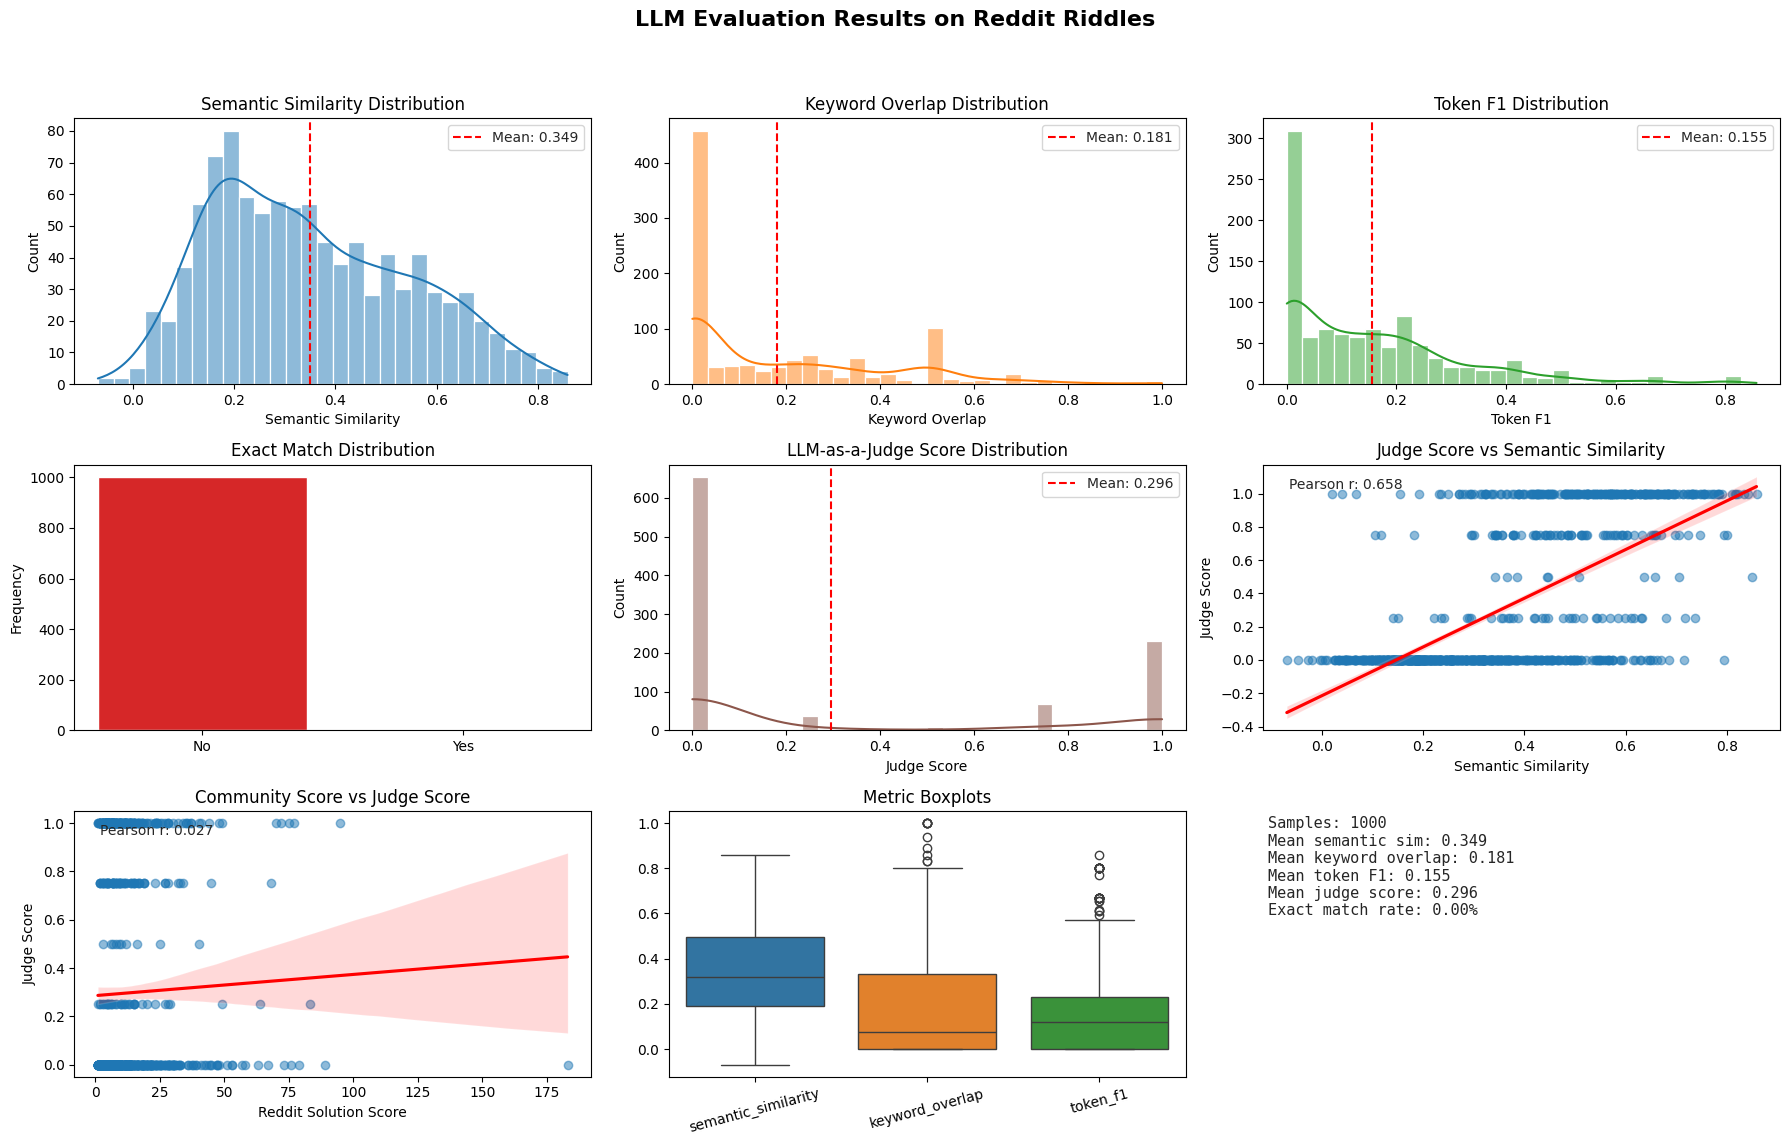

(<Figure size 1800x1200 with 9 Axes>,
 array([[<Axes: title={'center': 'Semantic Similarity Distribution'}, xlabel='Semantic Similarity', ylabel='Count'>,
         <Axes: title={'center': 'Keyword Overlap Distribution'}, xlabel='Keyword Overlap', ylabel='Count'>,
         <Axes: title={'center': 'Token F1 Distribution'}, xlabel='Token F1', ylabel='Count'>],
        [<Axes: title={'center': 'Exact Match Distribution'}, ylabel='Frequency'>,
         <Axes: title={'center': 'LLM-as-a-Judge Score Distribution'}, xlabel='Judge Score', ylabel='Count'>,
         <Axes: title={'center': 'Judge Score vs Semantic Similarity'}, xlabel='Semantic Similarity', ylabel='Judge Score'>],
        [<Axes: title={'center': 'Community Score vs Judge Score'}, xlabel='Reddit Solution Score', ylabel='Judge Score'>,
         <Axes: title={'center': 'Metric Boxplots'}>, <Axes: >]],
       dtype=object))

In [16]:
# Create visualizations
plot_evaluation_metrics(results_df)

In [17]:
# Option 2: Extract with LLM strategy on full dataset (uncomment to run)
# WARNING: This will make many API calls and take a long time
sample_size = 1000
max_workers = 10  # Adjust based on API rate limits (5-20 recommended)

print("="*80)
print(f"EXTRACTING PAIRS WITH LLM-BASED STRATEGY (Parallel Processing)")
# print(f"Sample size: {sample_size}, Workers: {max_workers}")
print("="*80)

pairs_df_llm = extract_problem_solution_pairs(
    posts_df, 
    comments_df, 
    use_top_level_only=True,
    strategy="llm_based",
    llm_model="openai/gpt-4o-mini",
    sample_size=sample_size,
    max_workers=max_workers  # Add max_workers parameter for parallel processing
)

# pairs_df_llm = extract_problem_solution_pairs(
#     posts_df, 
#     comments_df, 
#     use_top_level_only=True,
#     strategy="llm_based",
#     llm_model="openai/gpt-4o-mini",
#     max_workers=max_workers  # Add max_workers parameter for parallel processing
# )
# Save LLM-based pairs
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_file = f"pairs_llm_based_{timestamp}.json"
pairs_df_llm.to_json(output_file, orient='records', indent=2)
print(f"\nLLM-based pairs saved to {output_file}")

# Use LLM-based pairs for evaluation
pairs_df = pairs_df_llm


EXTRACTING PAIRS WITH LLM-BASED STRATEGY (Parallel Processing)
Filtered to 5691 solved self-posts
Processing 1000 posts
Valid comments: 345153
Using strategy: llm_based
Using parallel processing with 10 workers...
Note: Please, adjust max_workers based on your API rate limits, in my case I use 10 workers for default.


Extracting pairs (parallel): 100%|██████████| 1000/1000 [01:36<00:00, 10.37it/s]



Extracted 823 problem/solution pairs
LLM rejected 177 posts (no satisfactory answer found)
Rejection rate: 17.7%

LLM-based pairs saved to pairs_llm_based_20251114_165501.json


In [18]:
# Evaluate on a sample of riddles (now with parallel processing - much faster!)
# You can increase max_samples or remove it to evaluate on all pairs

sample_size = 1000
max_workers = 10  # Adjust based on API rate limits (5-20 recommended)

# print(f"Evaluating on {sample_size} sample riddles...")
print(f"Using {max_workers} parallel workers for faster processing")

# Evaluate with GPT-4o-mini (now with parallel processing)
results_df = evaluate_llm_on_riddles(
    pairs_df, 
    model="openai/gpt-4o-mini",
    save_results=True,
    max_samples=sample_size,
    max_workers=max_workers  # Add parallel processing!
)
# results_df = evaluate_llm_on_riddles(
#     pairs_df, 
#     model="openai/gpt-4o-mini",
#     save_results=True,
#     max_samples=sample_size,
#     max_workers=max_workers  # Add parallel processing!
# )

Using 10 parallel workers for faster processing
Evaluating openai/gpt-4o-mini on 823 riddles...
Using parallel processing with 10 workers...
Note: Adjust max_workers based on your API rate limits


Evaluating openai/gpt-4o-mini: 100%|██████████| 823/823 [04:47<00:00,  2.86it/s]


Results saved to evaluation_results_openai_gpt-4o-mini_20251114_165948.json


In [19]:
# Analyze results
display_evaluation_summary(results_df)
display_sample_results(results_df, n=3, show_best=True)
display_sample_results(results_df, n=3, show_best=False)

EVALUATION SUMMARY
Total samples: 823
Exact match rate: 0.00%
Average semantic similarity: 0.402
Average keyword overlap: 0.214
Average token F1: 0.190
Average judge score: 0.389
High similarity rate (>= 0.7): 7.29%
Perfect matches: 0.0

SAMPLE RESULTS (BEST 3) sorted by semantic_similarity

Post ID: 73q7xw
Semantic Similarity: 0.975
Token F1: 1.000
Exact Match: No
Judge Score: 1.000

Problem (first 150 chars): Help me please! A childhood hero...

I'm not sure this classifies as a riddle so I'm sorry if I'm breaking the rules! My boyfriend wants me to guess h...

Ground Truth: Nelson Horatio
Predicted: Horatio Nelson

--------------------------------------------------------------------------------

Post ID: 6wc5cd
Semantic Similarity: 0.878
Token F1: 0.396
Exact Match: No
Judge Score: 1.000

Problem (first 150 chars): The door to freedom

You have been captured by a crazy scientist who wants to play a game with you. You are put in a room with two doors; one is leadi...

Ground Truth: [

/tmp/ipykernel_743/1568971671.py:188: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(list(box_data.keys()), rotation=15)


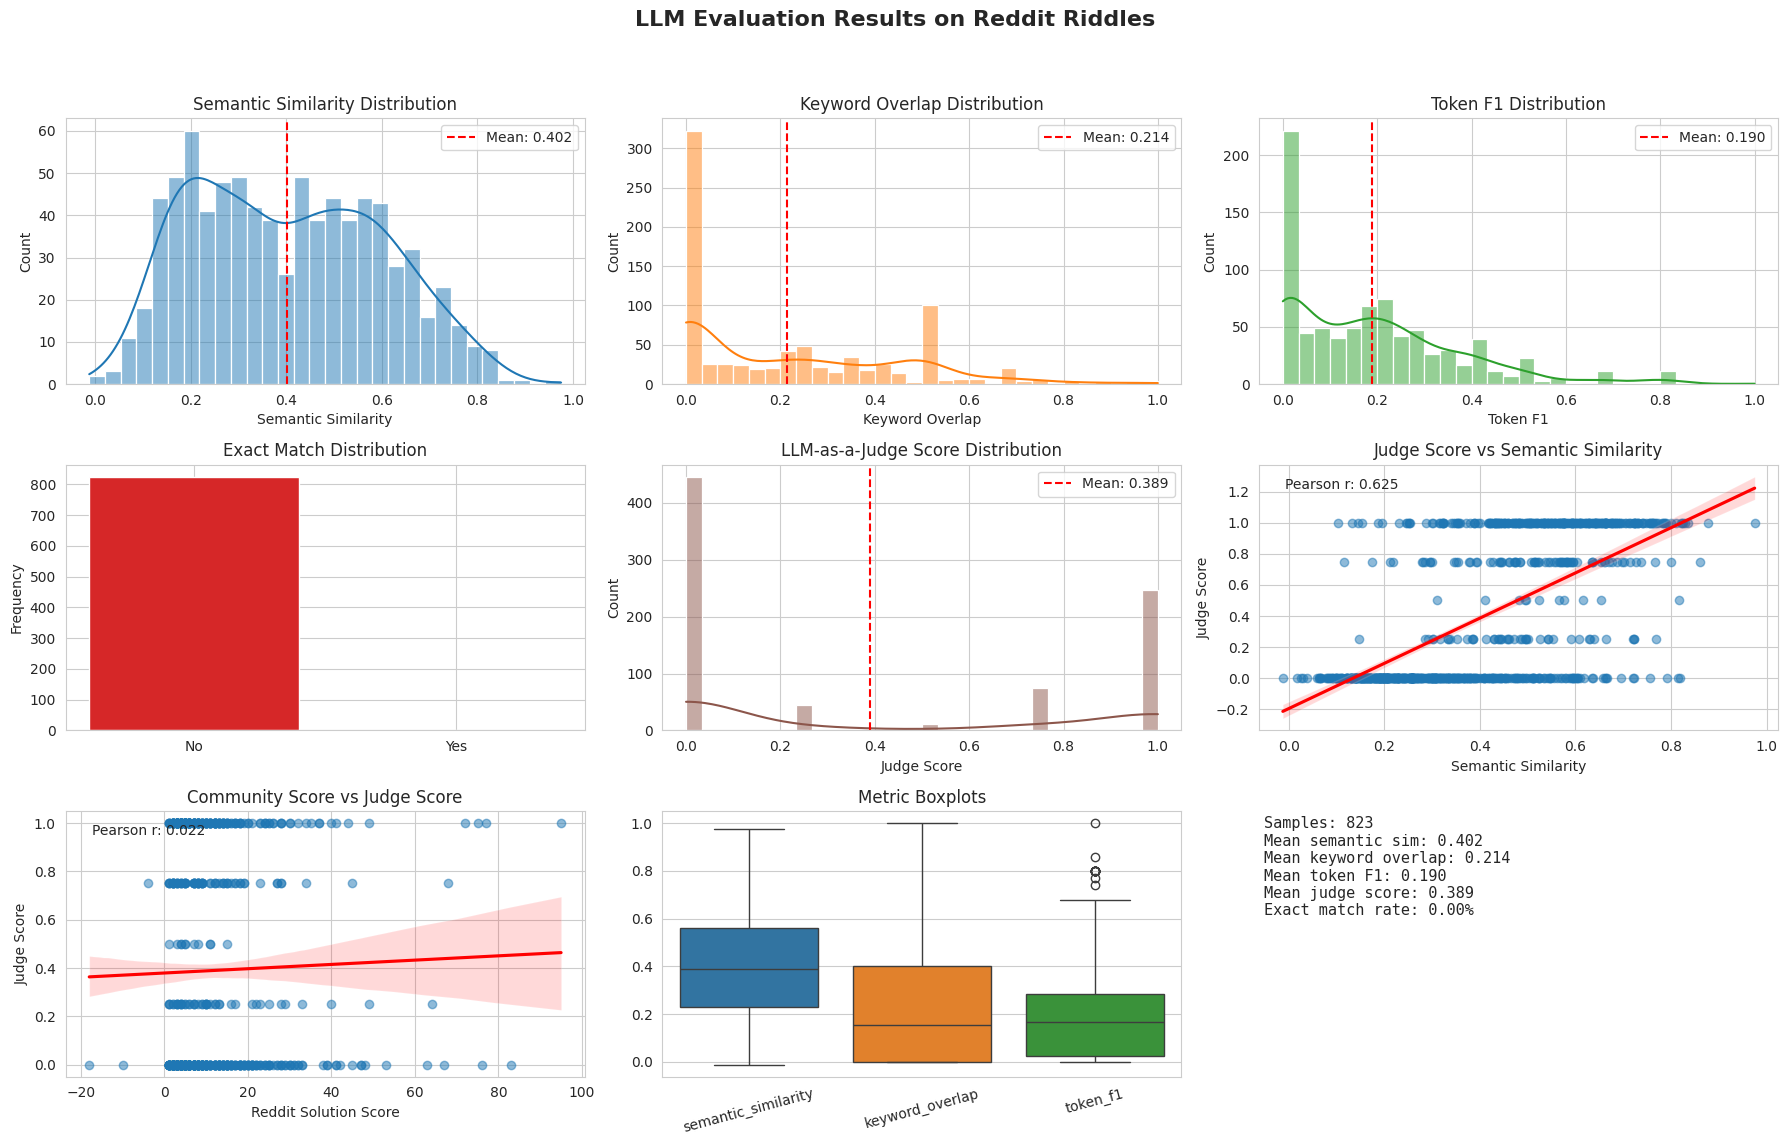

(<Figure size 1800x1200 with 9 Axes>,
 array([[<Axes: title={'center': 'Semantic Similarity Distribution'}, xlabel='Semantic Similarity', ylabel='Count'>,
         <Axes: title={'center': 'Keyword Overlap Distribution'}, xlabel='Keyword Overlap', ylabel='Count'>,
         <Axes: title={'center': 'Token F1 Distribution'}, xlabel='Token F1', ylabel='Count'>],
        [<Axes: title={'center': 'Exact Match Distribution'}, ylabel='Frequency'>,
         <Axes: title={'center': 'LLM-as-a-Judge Score Distribution'}, xlabel='Judge Score', ylabel='Count'>,
         <Axes: title={'center': 'Judge Score vs Semantic Similarity'}, xlabel='Semantic Similarity', ylabel='Judge Score'>],
        [<Axes: title={'center': 'Community Score vs Judge Score'}, xlabel='Reddit Solution Score', ylabel='Judge Score'>,
         <Axes: title={'center': 'Metric Boxplots'}>, <Axes: >]],
       dtype=object))

In [20]:
# Create visualizations
plot_evaluation_metrics(results_df)

We also try to see some example and why the result of the metric is low

In [21]:
def display_low_quality_examples(results_df, n=5, similarity_threshold=0.3, judge_threshold=0.3):
    '''
    Displays examples of riddles where both semantic similarity and judge scores are low.
    
    These are cases where the LLM's predicted answer poorly matches the ground truth,
    helping identify failure modes and edge cases.
    
    :param results_df: DataFrame with evaluation results
    :param n: Number of low-quality examples to display (default = 5)
    :param similarity_threshold: Maximum semantic similarity to consider "low" (default = 0.3)
    :param judge_threshold: Maximum judge score to consider "low" (default = 0.3)
    :type results_df: pd.DataFrame
    :type n: int
    :type similarity_threshold: float
    :type judge_threshold: float
    '''
    # Helper to safely extract judge scores
    def _extract_judge_score(judge_val):
        if isinstance(judge_val, dict) and 'judge_score' in judge_val:
            return judge_val['judge_score']
        elif isinstance(judge_val, (int, float)):
            return float(judge_val)
        return np.nan
    
    # Filter for low-quality predictions
    results_df_copy = results_df.copy()
    results_df_copy['judge_score_numeric'] = results_df_copy['judge_score'].apply(_extract_judge_score)
    
    low_quality = results_df_copy[
        (results_df_copy['semantic_similarity'] <= similarity_threshold) &
        (results_df_copy['judge_score_numeric'] <= judge_threshold)
    ].sort_values('semantic_similarity').head(n)
    
    print("="*100)
    print(f"LOW-QUALITY EXAMPLES (Semantic Similarity ≤ {similarity_threshold}, Judge Score ≤ {judge_threshold})")
    print(f"Found {len(low_quality)} examples matching criteria")
    print("="*100)
    
    if len(low_quality) == 0:
        print("No examples found matching the criteria.")
        return
    
    for idx, (_, row) in enumerate(low_quality.iterrows(), 1):
        print(f"\n{'─'*100}")
        print(f"EXAMPLE {idx}/{len(low_quality)}")
        print(f"{'─'*100}")
        print(f"Post ID: {row['post_id']}")
        print(f"Model: {row['model']}")
        print(f"\n METRICS:")
        print(f"  • Semantic Similarity: {row['semantic_similarity']:.3f} (LOW)")
        print(f"  • Judge Score: {row['judge_score_numeric']:.3f} (LOW)")
        print(f"  • Token F1: {row.get('token_f1', np.nan):.3f}")
        print(f"  • Keyword Overlap: {row.get('keyword_overlap', np.nan):.3f}")
        print(f"  • Exact Match: {'Yes' if row.get('exact_match', 0) else 'No'}")
        
        print(f"\n❓ PROBLEM (Riddle):")
        problem_text = row['problem']
        if len(problem_text) > 300:
            print(f"  {problem_text[:300]}...\n  [truncated]")
        else:
            print(f"  {problem_text}")
        
        print(f"\n✅ GROUND TRUTH (Expected Answer):")
        print(f"  {row['ground_truth']}")
        
        print(f"\n❌ PREDICTED (LLM's Answer):")
        print(f"  {row['predicted_answer']}")
        
        print(f"\n💭 ANALYSIS:")
        print(f"  Why might this be a mismatch?")
        print(f"  - Ground truth length: {len(row['ground_truth'].split())} words")
        print(f"  - Predicted length: {len(row['predicted_answer'].split())} words")
        
        # Check for common failure patterns
        if len(row['predicted_answer']) < 5:
            print(f"  ⚠️  Predicted answer is suspiciously short")
        if "i don't know" in row['predicted_answer'].lower() or "unsure" in row['predicted_answer'].lower():
            print(f"  ⚠️  LLM expressed uncertainty")
        if row['semantic_similarity'] > 0.1 and row['semantic_similarity'] < 0.3:
            print(f"  ⚠️  Partial semantic overlap detected - answers may be tangentially related")
    
    print(f"\n{'='*100}\n")


# Display low-quality examples
display_low_quality_examples(results_df, n=5, similarity_threshold=0.3, judge_threshold=0.3)

LOW-QUALITY EXAMPLES (Semantic Similarity ≤ 0.3, Judge Score ≤ 0.3)
Found 5 examples matching criteria

────────────────────────────────────────────────────────────────────────────────────────────────────
EXAMPLE 1/5
────────────────────────────────────────────────────────────────────────────────────────────────────
Post ID: 1pqpdp
Model: openai/gpt-4o-mini

 METRICS:
  • Semantic Similarity: -0.012 (LOW)
  • Judge Score: 0.000 (LOW)
  • Token F1: 0.000
  • Keyword Overlap: 0.000
  • Exact Match: No

❓ PROBLEM (Riddle):
  Home

Working and working all the day long,    
I'm less than one less than the lines in this song.    
Two pushing out, and two more pulling in;    
listen real close and you'll hear quite a din.

---

Once again, I would appreciate any feedback you have to give.

Edit: Here's an attempt at a secon...
  [truncated]

✅ GROUND TRUTH (Expected Answer):
  [Oh! Heart?](/sp)

❌ PREDICTED (LLM's Answer):
  The answer to the riddle is "Home." 

Here's the reasoning:

1. **"W

## Conclusion: Comparison of Score-Based vs LLM-Based Strategies

### Executive Summary

This evaluation compared two strategies for extracting ground-truth solutions from Reddit riddle threads. Due to API credit constraints, we evaluated on a subset of the full dataset (1,000 riddles for score-based, 823 for LLM-based).

---

### Strategy Comparison

#### 1. Score-Based Strategy
Selects the highest-scoring comment (by Reddit upvotes) as the ground-truth answer.

| Metric | Value |
|--------|-------|
| Samples | 1,000 |
| Mean semantic similarity | 0.349 |
| Mean keyword overlap | 0.181 |
| Mean token F1 | 0.155 |
| Mean judge score | 0.296 |
| Exact match rate | 0.00% |

#### 2. LLM-Based Strategy
Uses an LLM to evaluate the top 30 comments per riddle and selects the best answer, or rejects all if none are satisfactory.

| Metric | Value | Improvement |
|--------|-------|-------------|
| Samples | 823 (17.7% rejection) | – |
| Mean semantic similarity | 0.402 | +15% |
| Mean keyword overlap | 0.214 | +18% |
| Mean token F1 | 0.190 | +23% |
| Mean judge score | 0.389 | +31% |
| Exact match rate | 0.00% | – |

---


### By look at these visuals

**1. LLM-based strategy yields significantly higher quality ground truth**
- All evaluation metrics show consistent improvements across the board, indicating that LLM filtering effectively removes low-quality or incorrect solutions that may have accumulated upvotes through visibility or popularity bias.

**2. Quality-over-quantity trade-off is worthwhile**
- The 17.7% rejection rate reduces dataset size (823 vs 1,000 samples) but produces more reliable ground truth. This is beneficial for model training and evaluation.

**3. Semantic matching is essential for riddle evaluation**
- The 0% exact match rate across both strategies demonstrates that riddle answers rarely match word-for-word, even when semantically equivalent. This validates our multi-metric evaluation approach.
- Strong correlation between judge scores and semantic similarity (r ≈ 0.63–0.66) confirms that LLM judgment aligns well with embeddings-based similarity.

**4. Community upvotes are a poor proxy for correctness**
- Negligible correlation (r ≈ 0.02–0.03) between Reddit scores and LLM judge assessments reveals that popular answers are not reliably correct. This underscores why semantic and LLM-based evaluation is necessary.

**5. LLM-as-judge produces clear-cut decisions**
- The bimodal distribution of judge scores (clustering near 0.0 or 1.0) suggests the LLM makes definitive judgments rather than nuanced gradations, which is appropriate for riddle correctness.

---


### After many execution, we recommand:

- **For high-quality datasets:** Prioritize the LLM-based strategy. The computational cost is justified by significantly better ground truth, especially if the dataset will be used for training or rigorous benchmarking.

- **For rapid prototyping:** Use score-based strategy as a faster, cheaper baseline. Consider post-processing to filter obviously low-quality answers.

- **For evaluation:** Rely on semantic similarity scores and LLM-as-a-judge metrics rather than exact matching or raw community scores. These better capture the nuanced nature of riddle answers.

---